In [5]:
from pathlib import Path
import pandas as pd


def read_sensor_csv(file_path: str | Path) -> pd.DataFrame:
    """Reads a single VCNL sensor log CSV into a formatted Pandas DataFrame."""
    file_path = Path(file_path)
    df = pd.read_csv(file_path)

    # Standardize column name for light reading
    if "ambient_light" in df.columns:
        df.rename(columns={"ambient_light": "als"}, inplace=True)

    # Extract serial number from filename (e.g. "500_1001.CSV" -> "500")
    serial_num = file_path.stem.split("_")[0]
    df["serial_number"] = serial_num

    # Construct high-precision datetime index if time was synced
    if "timestamp" in df.columns and (df["timestamp"] > 0).any():
        sync_idx = (df["timestamp"] > 0).idxmax()
        base_epoch = df.loc[sync_idx, "timestamp"]
        base_millis = df.loc[sync_idx, "millis"]

        millis_delta = df["millis"] - base_millis
        df["datetime"] = pd.to_datetime(
            base_epoch, unit="s"
        ) + pd.to_timedelta(millis_delta, unit="ms")
        df.set_index("datetime", inplace=True)

    return df


def load_synchronized_master(
    dir_path: str | Path = "OBS_logs", grid_freq: str = "50ms"
) -> pd.DataFrame:
    """Stitches sequential files per sensor, uniquely prefixes columns with SN & Model,

    and aligns all sensors side-by-side onto a single synchronized timeline.
    """
    dir_path = Path(dir_path)
    csv_files = list(dir_path.glob("*.CSV")) + list(dir_path.glob("*.csv"))

    if not csv_files:
        raise FileNotFoundError(f"No CSV files found in {dir_path.resolve()}")

    # 1. Parse all CSV files
    raw_dfs = [read_sensor_csv(f) for f in csv_files]

    # 2. Group files by unique sensor identity (Serial Number + Sensor Model)
    sensor_groups = {}
    for df in raw_dfs:
        sn = df["serial_number"].iloc[0]
        sensor_type = (
            df["sensor_type"].iloc[0]
            if "sensor_type" in df.columns
            else "UNKNOWN"
        )
        sensor_key = (sn, sensor_type)

        # Retain only numerical measurement columns
        measurement_cols = [
            c
            for c in ["proximity", "als", "lux", "white"]
            if c in df.columns
        ]
        df_measurements = df[measurement_cols]

        if sensor_key not in sensor_groups:
            sensor_groups[sensor_key] = []
        sensor_groups[sensor_key].append(df_measurements)

    # 3. Stitch sequential logs per sensor & prefix column names
    processed_sensors = []
    for (sn, sensor_type), df_list in sensor_groups.items():
        # Combine sequential files from the same sensor vertically
        combined_sensor = pd.concat(df_list, axis=0).sort_index()

        # Snap timestamps to 50ms grid to align independent microcontroller clocks
        if isinstance(combined_sensor.index, pd.DatetimeIndex):
            combined_sensor.index = combined_sensor.index.round(grid_freq)
            # Average duplicate values if multiple readings land on the same 50ms bin
            combined_sensor = combined_sensor.groupby(
                combined_sensor.index
            ).mean()

        # Rename columns: e.g. "SN500_VCNL4010_proximity"
        prefix = f"SN{sn}_{sensor_type}"
        combined_sensor = combined_sensor.add_prefix(f"{prefix}_")

        processed_sensors.append(combined_sensor)

    # 4. Synchronize all sensors horizontally (outer join on DatetimeIndex)
    master_df = pd.concat(processed_sensors, axis=1).sort_index()

    return master_df


# ==========================================
# Example Usage
# ==========================================
if __name__ == "__main__":
    # Load all sensors synchronized side-by-side
    master_df = load_synchronized_master("OBS_logs", grid_freq="50ms")

    print("--- Synchronized Master DataFrame ---")
    print(master_df.head(10))
    print("\nMaster Columns:")
    for col in master_df.columns:
        print(f" - {col}")

--- Synchronized Master DataFrame ---
                         SN150_VCNL4010_proximity  SN150_VCNL4010_als  \
datetime                                                                
2026-10-13 06:45:16.000                   13214.0              2304.0   
2026-10-13 06:45:16.050                   13214.0              2304.0   
2026-10-13 06:45:16.100                   13214.0              2304.0   
2026-10-13 06:45:16.150                   13214.0              2304.0   
2026-10-13 06:45:16.200                   13214.0              2304.0   
2026-10-13 06:45:16.250                   13214.0              2304.0   
2026-10-13 06:45:16.300                   13214.0              2048.0   
2026-10-13 06:45:16.350                   13726.0              2048.0   
2026-10-13 06:45:16.400                   13726.0              2048.0   
2026-10-13 06:45:16.450                   13726.0              2048.0   

                         SN150_VCNL4040_proximity  SN150_VCNL4040_als  \
datetime    

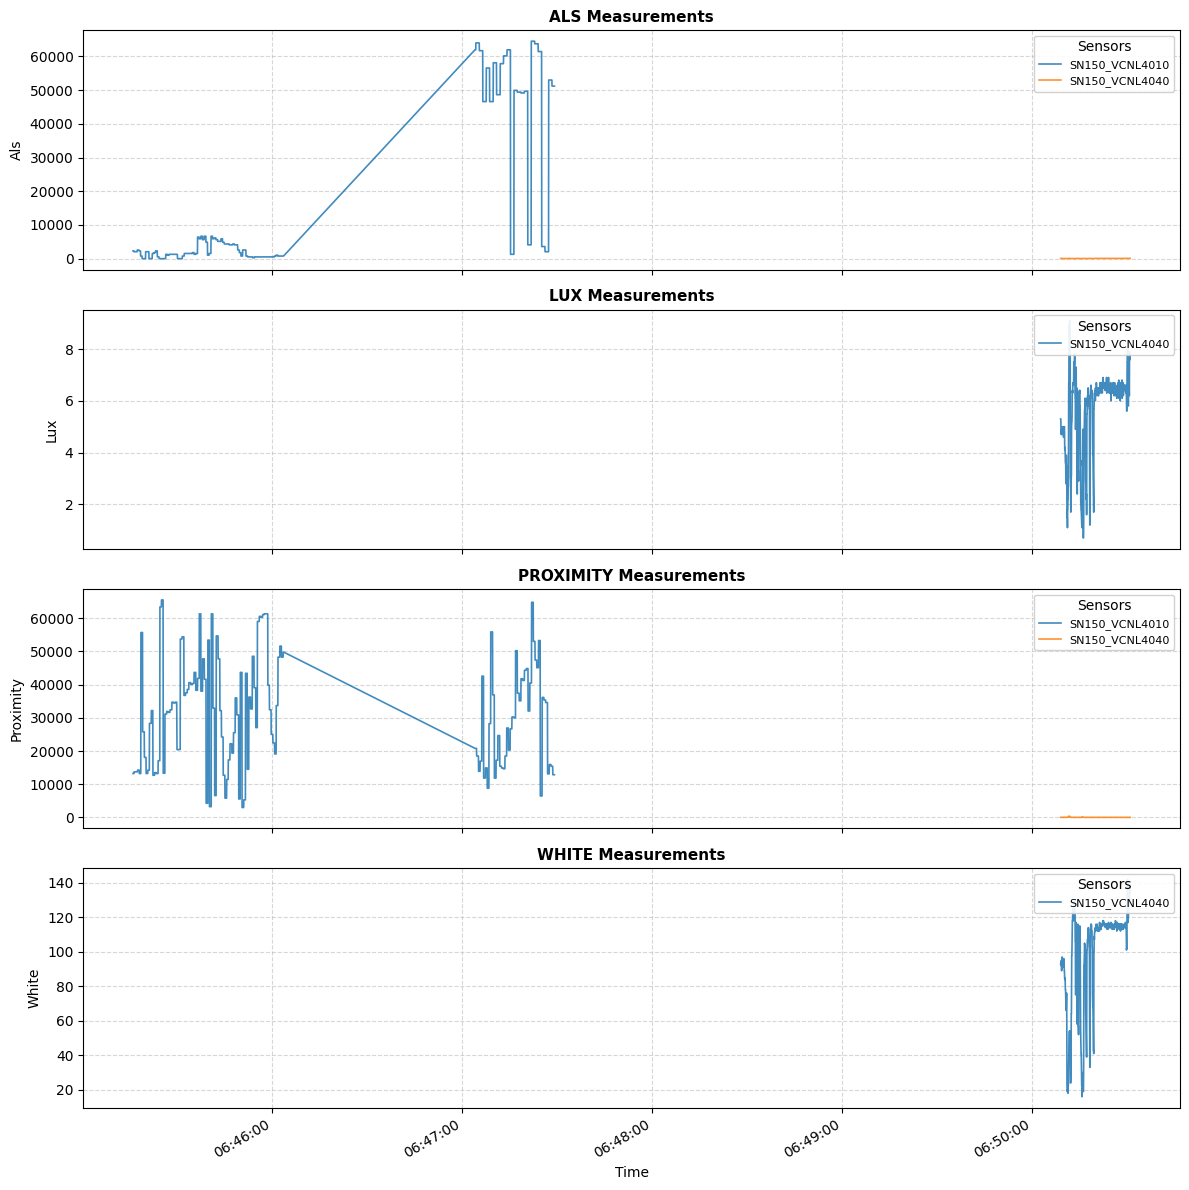

In [11]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd


def plot_synchronized_sensors(
    df: pd.DataFrame, smooth_window: str | None = None
):
    """Plots synchronized sensor time series split by measurement metric.

    Parameters:
    - df: Master DataFrame with DatetimeIndex.
    - smooth_window: Optional pandas offset string (e.g., '250ms' or '1s') for
    a rolling mean filter.
    """
    if df.empty:
        print("DataFrame is empty.")
        return

    # Apply optional rolling mean smoothing for high-frequency noise
    plot_df = (
        df.rolling(smooth_window).mean() if smooth_window else df.copy()
    )

    # Extract unique metric types from column names (e.g., 'proximity', 'als', 'lux', 'white')
    metrics = sorted(list({col.rsplit("_", 1)[-1] for col in df.columns}))

    fig, axes = plt.subplots(
        nrows=len(metrics),
        ncols=1,
        figsize=(12, 3 * len(metrics)),
        sharex=True,
    )

    # Ensure axes is iterable if there's only 1 metric
    if len(metrics) == 1:
        axes = [axes]

    # Color palette
    colors = plt.cm.tab10.colors

    for ax, metric in zip(axes, metrics):
        # Find all columns matching this metric
        metric_cols = [c for c in df.columns if c.endswith(f"_{metric}")]

        for i, col in enumerate(metric_cols):
            # Strip metric suffix for cleaner legend labels (e.g., "SN500_VCNL4010")
            sensor_label = col.rsplit(f"_{metric}", 1)[0]
            ax.plot(
                plot_df.index,
                plot_df[col],
                label=sensor_label,
                alpha=0.85,
                linewidth=1.2,
                color=colors[i % len(colors)],
            )

        ax.set_title(
            f"{metric.upper()} Measurements", fontsize=11, fontweight="bold"
        )
        ax.set_ylabel(metric.capitalize(), fontsize=10)
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.legend(
            loc="upper right", framealpha=0.9, fontsize=8, title="Sensors"
        )

    # Format x-axis timestamps
    axes[-1].set_xlabel("Time", fontsize=10)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
    fig.autofmt_xdate()

    plt.tight_layout()
    plt.show()


# Example Usage:
plot_synchronized_sensors(master_df)
# plot_synchronized_sensors(master_df, smooth_window="250ms")  # 5-sample rolling mean

In [13]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def plot_interactive_sensors(df: pd.DataFrame):
    """Creates an interactive multi-panel time-series chart with linked zoom controls."""
    metrics = sorted(list({col.rsplit("_", 1)[-1] for col in df.columns}))

    fig = make_subplots(
        rows=len(metrics),
        cols=1,
        shared_xaxes=True,
        subplot_titles=[f"{m.upper()} Readings" for m in metrics],
        vertical_spacing=0.08,
    )

    for row_idx, metric in enumerate(metrics, start=1):
        metric_cols = [c for c in df.columns if c.endswith(f"_{metric}")]

        for col in metric_cols:
            sensor_label = col.rsplit(f"_{metric}", 1)[0]
            fig.add_trace(
                go.Scatter(
                    x=df.index,
                    y=df[col],
                    mode="lines",
                    name=f"{sensor_label} ({metric})",
                    legendgroup=sensor_label,
                ),
                row=row_idx,
                col=1,
            )

    fig.update_layout(
        height=300 * len(metrics),
        title_text="Synchronized VCNL Sensor Telemetry (50ms Cadence)",
        hovermode="x unified",
        template="plotly_white",
    )

    fig.show()


# Example Usage:
plot_interactive_sensors(master_df)